# Real-Time PI Data Retrieval & Press 1 Quality Analysis

This notebook retrieves real-time process & lab quality data via the **MI Cube API** (`InterpolatedValue/MultiTag/`) from the **AVEVA PI Server (`VPKGDRBPPI01`)**.
The goal is to analyze **Press 1 pulp quality** (Kappa, Viscosity, Brightness) and plot **Probability Density Bell Curves** and **Heatmaps** directly.

In [14]:
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style with thinner font weight
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['Tahoma', 'DejaVu Sans']
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['axes.titleweight'] = 'normal'
plt.rcParams['axes.labelweight'] = 'normal'
plt.rcParams['axes.unicode_minus'] = False
print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


## 1. Configure API Endpoint & Target PI Tags

In [15]:
# MI Cube API Endpoint for multi-tag interpolated data retrieval
MI_CUBE_API_URL = "https://micube.scg.com/v2/api/Datacenter/PIServer/InterpolatedValue/MultiTag/"
API_TOKEN = "76ED1A0F-7386-432B-B586-5A8304AE20FB"
PI_SERVER = "VPKGDRBPPI01"

# Target PI Tags (Batch Statuses + Press 1 Lab Quality Metrics)
TAGS = [
    "PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status",
    "PULP-LINE2-KAPPA-PRESS1",
    "PULP-LINE2-VISCOSITY-PRESS1",
    "PULP-LINE2-BRIGHTNESS-PRESS1",
    "PM2.105FIC303:MV", # WHLiqu to DilSrew
    "PM2.305FIC036:MV",  # MP Steam Pulp Heat
    "PM2.Prod.ODL", # Production ODL
    "PM2.105NIC207:MV", #Press 1 Feed Cons
    "PM2.106FIC006:MV", #Deknotting Feed Flow
    
]

# Time range settings
START_TIME = "2026-08-01 00:00:00"
END_TIME = "2026-08-20 00:00:00"
INTERVAL = "30m"

print(f"Target Endpoint : {MI_CUBE_API_URL}")
print(f"Total Tags      : {len(TAGS)}")

Target Endpoint : https://micube.scg.com/v2/api/Datacenter/PIServer/InterpolatedValue/MultiTag/
Total Tags      : 12


## 2. Execute HTTP POST Request to MI Cube API

In [16]:
payload = {
    "token": API_TOKEN,
    "server": PI_SERVER,
    "tags": TAGS,
    "start_time": START_TIME,
    "end_time": END_TIME,
    "interval": INTERVAL
}

headers = {
    'Content-Type': 'application/json',
    'Accept': 'application/json'
}

print("Sending POST Request to MI Cube API...")
try:
    response = requests.post(MI_CUBE_API_URL, json=payload, headers=headers, timeout=30)
    print(f"Status Code: {response.status_code}")
    if response.status_code == 200:
        data = response.json()
        print(" Fetch Success! Response Preview:")
        print(json.dumps(data, indent=2)[:500])
    else:
        print(f" API Request Failed: {response.text}")
except Exception as e:
    print(f" Connection Error: {e}")

Sending POST Request to MI Cube API...
Status Code: 200
 Fetch Success! Response Preview:
{
  "status": "success",
  "message": "Interpolated values retrieved successfully",
  "results": {
    "PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status": [
      {
        "timestamp": "2026-08-01T00:00:00+00:00",
        "value": 0.06010517799352751,
        "description": "",
        "unit": ""
      },
      {
        "timestamp": "2026-08-01T00:30:00+00:00",
        "value": 0.07071197411003236,
        "description": "",
        "unit": ""
      },
      {
        "timestamp": "2026-08


## 3. Parse JSON Response into Pandas DataFrame

In [17]:
if 'response' in locals() and response.status_code == 200:
    # Parse JSON structure
    if isinstance(data, dict) and 'results' in data:
        raw_results = data['results']
    elif isinstance(data, list):
        raw_results = data
    else:
        raw_results = [data]
        
    # Standardize long-format DataFrame
    if isinstance(raw_results, dict):
        df_list = []
        for tag, records in raw_results.items():
            tmp = pd.DataFrame(records)
            tmp['tag'] = tag
            df_list.append(tmp)
        df_long = pd.concat(df_list, ignore_index=True)
    else:
        df_long = pd.DataFrame(raw_results)
        
    print(f" Raw Data Parsed: {len(df_long)} records.")
    display(df_long.head(10))
else:
    print(" No response data available to process.")

 Raw Data Parsed: 10956 records.


,timestamp,value,description,unit,tag
0,2026-08-01T00:00:00+00:00,0.060105,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
1,2026-08-01T00:30:00+00:00,0.070712,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
2,2026-08-01T01:00:00+00:00,0.081319,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
3,2026-08-01T01:30:00+00:00,0.091926,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
4,2026-08-01T02:00:00+00:00,0.102532,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
5,2026-08-01T02:30:00+00:00,0.846175,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
6,2026-08-01T03:00:00+00:00,1.000000,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
7,2026-08-01T03:30:00+00:00,1.000000,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
8,2026-08-01T04:00:00+00:00,0.000000,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
9,2026-08-01T04:30:00+00:00,0.000000,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...


## 4. Press 1 Pulp Quality Analysis & Bell Curve Visualizations

In [18]:
# Data Reshaping, Specific Consumption Calculation & Active Digester Assignment
if 'df_long' in locals() and not df_long.empty:
    # 1. Standardize column names
    col_map = {col: col.lower() for col in df_long.columns}
    df_long = df_long.rename(columns=col_map)
    
    # 2. Pivot long format to wide format (Timestamp as Index, Tags as Columns)
    time_col = 'timestamp' if 'timestamp' in df_long.columns else 'time'
    tag_col = 'tag' if 'tag' in df_long.columns else 'tagname'
    val_col = 'value' if 'value' in df_long.columns else 'val'
    
    df_wide = df_long.pivot_table(index=time_col, columns=tag_col, values=val_col, aggfunc='first').reset_index()
    df_wide[time_col] = pd.to_datetime(df_wide[time_col])
    df_wide = df_wide.sort_values(time_col).reset_index(drop=True)
    
    # 3. Coerce numeric columns
    for col in df_wide.columns:
        if col != time_col:
            df_wide[col] = pd.to_numeric(df_wide[col], errors='coerce')
            
    # 4. Map Active Digester (D1 - D4)
    status_cols = {
        'D1': 'PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status',
        'D2': 'PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status',
        'D3': 'PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status',
        'D4': 'PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status'
    }
    
    def get_active_digester(row):
        for dig, col in status_cols.items():
            if col in row and row[col] > 0:
                return dig
        return 'D1'  # Default fallback
        
    df_wide['Digester_ID'] = df_wide.apply(get_active_digester, axis=1)

    # 5. Compute Specific Consumption Metrics (Specific White Liquor & Specific Steam)
    wl_tag = "PM2.105FIC303:MV"
    steam_tag = "PM2.305FIC036:MV"
    prod_tag = "PM2.Prod.ODL"

    if prod_tag in df_wide.columns:
        temp_prod = df_wide[prod_tag].copy()
        temp_prod[temp_prod <= 0] = np.nan
        
        if wl_tag in df_wide.columns:
            df_wide['Specific WHLiqu Consumption (m3_ADT)'] = 24.0 * df_wide[wl_tag] / temp_prod
        if steam_tag in df_wide.columns:
            df_wide['Specific Steam Consumption (t_ADT)'] = 24.0 * df_wide[steam_tag] / temp_prod

    print(" Real-time API Data Reshaped & Digester Assigned Successfully.")
    print("Batch Counts per Digester:")
    print(df_wide['Digester_ID'].value_counts())
    display(df_wide.head(10))
else:
    # Fallback to local clustered batch signatures for demonstration
    print(" Loading local dataset `df_clustered_batches.xlsx` for Press 1 Quality Analysis...")
    df_wide = pd.read_excel('df_clustered_batches.xlsx')
    if 'Digester_ID' in df_wide.columns:
        df_wide['Digester_ID'] = df_wide['Digester_ID'].apply(lambda x: f"D{int(x)}" if isinstance(x, (int, float)) else str(x))
    print(f"Loaded {len(df_wide)} records.")
    print("Batch Counts per Digester:")
    print(df_wide['Digester_ID'].value_counts())

 Real-time API Data Reshaped & Digester Assigned Successfully.
Batch Counts per Digester:
Digester_ID
D1    497
D2    230
D3    145
D4     41
Name: count, dtype: int64


tag,timestamp,PM2.105FIC303:MV,PM2.105NIC207:MV,PM2.106FIC006:MV,PM2.305FIC036:MV,PM2.Prod.ODL,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status,PULP-LINE2-BRIGHTNESS-PRESS1,PULP-LINE2-KAPPA-PRESS1,PULP-LINE2-VISCOSITY-PRESS1,Digester_ID,Specific WHLiqu Consumption (m3_ADT),Specific Steam Consumption (t_ADT)
0,2026-08-01 00:00:00+00:00,1.346662,3.851953,535.335938,1.095254,276.456970,0.060105,2.0,0.106690,0.0,35.000000,9.0000,816.000,D1,0.116907,0.095082
1,2026-08-01 00:30:00+00:00,1.336989,3.954141,561.585938,1.073652,269.881622,0.070712,0.0,0.083496,4.0,34.775002,9.1875,811.750,D1,0.118896,0.095478
2,2026-08-01 01:00:00+00:00,1.336468,3.921172,566.589844,1.061758,273.401154,0.081319,0.0,0.060303,4.0,34.549999,9.3750,807.500,D1,0.117319,0.093204
3,2026-08-01 01:30:00+00:00,1.340305,3.878438,553.929688,1.096895,272.017303,0.091926,0.0,0.037109,4.0,34.324997,9.5625,803.250,D1,0.118255,0.096779
4,2026-08-01 02:00:00+00:00,1.333478,3.831094,494.593750,1.155137,264.575775,0.102532,0.0,0.013916,4.0,34.099998,9.7500,799.000,D1,0.120961,0.104784
5,2026-08-01 02:30:00+00:00,1.339009,3.882656,464.679688,1.110566,268.219666,0.846175,0.0,0.000000,0.0,35.000000,9.9375,794.750,D1,0.119813,0.099372
6,2026-08-01 03:00:00+00:00,1.347389,3.997734,545.835938,1.047402,279.439575,1.000000,0.0,0.000000,0.0,35.900002,10.1250,790.500,D1,0.115722,0.089957
7,2026-08-01 03:30:00+00:00,1.271891,3.880312,489.781250,1.023066,257.219238,1.000000,0.0,0.000000,0.0,36.799999,10.3125,786.250,D1,0.118675,0.095458
8,2026-08-01 04:00:00+00:00,1.360656,3.881015,411.496094,0.991758,268.332184,0.000000,0.0,3.000000,0.0,37.700001,10.5000,782.000,D3,0.121699,0.088704
9,2026-08-01 04:30:00+00:00,1.329070,3.944531,548.925781,1.033457,269.140869,0.000000,0.0,3.000000,0.0,36.775002,10.2875,777.125,D3,0.118517,0.092156


### 5. Plot Press 1 Quality Probability Density Bell Curves (KDE Plots)

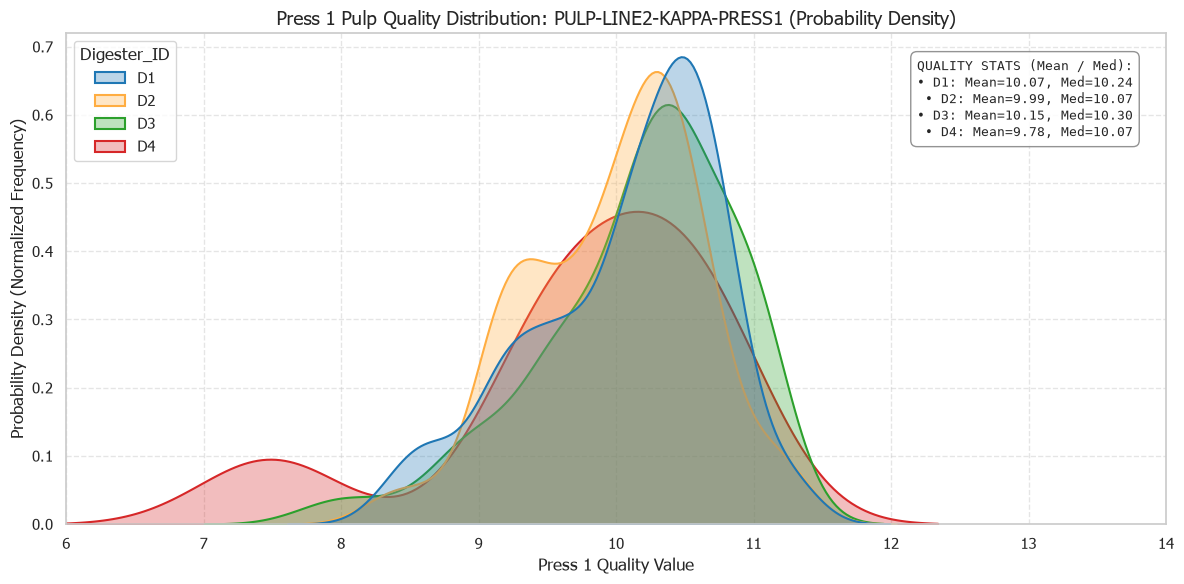

In [19]:
# Identify Press 1 quality parameter columns
kappa_col = [c for c in df_wide.columns if 'KAPPA' in c.upper() or 'Kappa' in c][0] if any('KAPPA' in c.upper() or 'Kappa' in c for c in df_wide.columns) else None
cons_col = [c for c in df_wide.columns if 'Press 1 Feed Cons' in c or 'CONS' in c.upper()][0] if any('CONS' in c.upper() for c in df_wide.columns) else None

palette = {'D1': '#1f77b4', 'D2': "#ffad41", 'D3': '#2ca02c', 'D4': '#d62728'}
digester_order = ['D1', 'D2', 'D3', 'D4']

# 1. Plot Kappa / Quality Metric Bell Curve
plt.figure(figsize=(12, 6))
if kappa_col and kappa_col in df_wide.columns:
    ax = sns.kdeplot(
        data=df_wide.dropna(subset=[kappa_col]),
        x=kappa_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
    )
    plt.xlim(6, 14)  # Compress X-axis view
    
    # Calculate Mean and Median per Digester
    valid_data = df_wide.dropna(subset=[kappa_col])
    stats_text = "QUALITY STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][kappa_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• {dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Quality Distribution: {kappa_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Quality Value', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print(" Kappa column not found in dataset. Please verify tag mapping.")

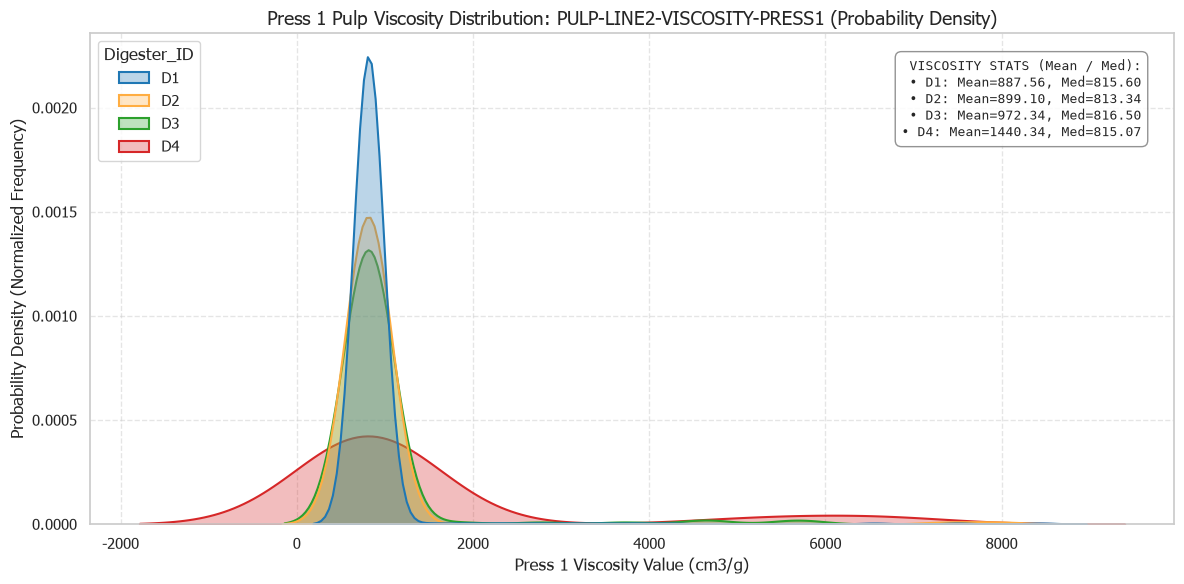

In [20]:
# 2. Plot Viscosity Bell Curve
visc_col = [c for c in df_wide.columns if 'VISCOSITY' in c.upper() or 'Viscosity' in c][0] if any('VISCOSITY' in c.upper() or 'Viscosity' in c for c in df_wide.columns) else None

plt.figure(figsize=(12, 6))
if visc_col and visc_col in df_wide.columns:
    ax = sns.kdeplot(
        data=df_wide.dropna(subset=[visc_col]),
        x=visc_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
    )
    
    # Calculate Mean and Median per Digester
    valid_data = df_wide.dropna(subset=[visc_col])
    stats_text = "VISCOSITY STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][visc_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• {dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Viscosity Distribution: {visc_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Viscosity Value (cm3/g)', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Viscosity column not found in dataset. Please verify tag mapping.")

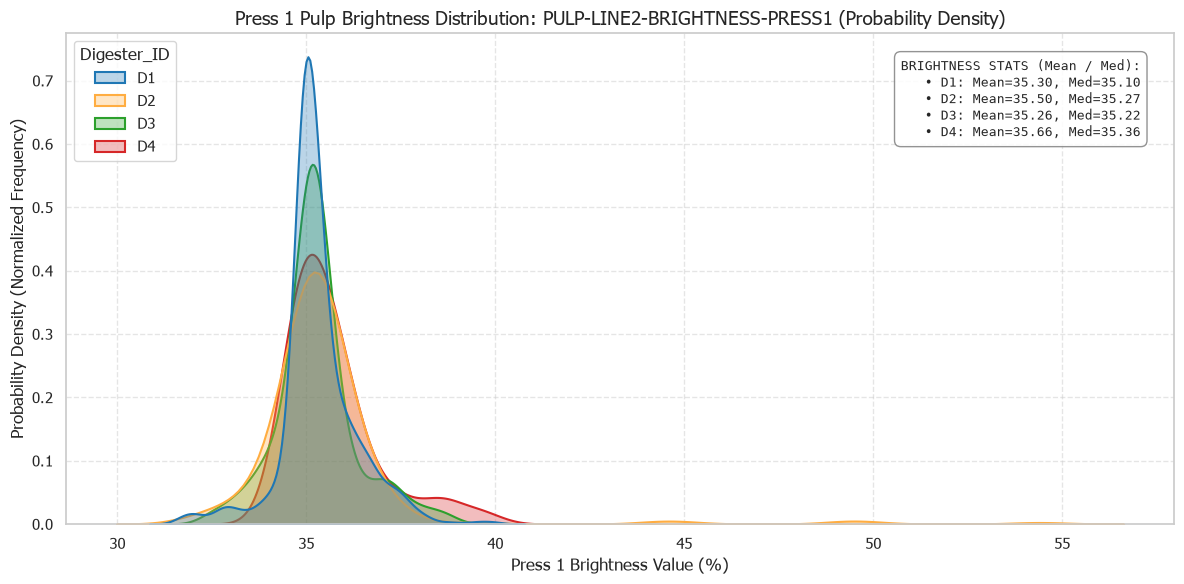

In [21]:
# 3. Plot Brightness Bell Curve
bright_col = [c for c in df_wide.columns if 'BRIGHTNESS' in c.upper() or 'Brightness' in c][0] if any('BRIGHTNESS' in c.upper() or 'Brightness' in c for c in df_wide.columns) else None

plt.figure(figsize=(12, 6))
if bright_col and bright_col in df_wide.columns:
    ax = sns.kdeplot(
        data=df_wide.dropna(subset=[bright_col]),
        x=bright_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
    )
    
    # Calculate Mean and Median per Digester
    valid_data = df_wide.dropna(subset=[bright_col])
    stats_text = "BRIGHTNESS STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][bright_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• {dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Brightness Distribution: {bright_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Brightness Value (%)', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Brightness column not found in dataset. Please verify tag mapping.")

### 6. Digester Quality Benchmark & Statistical Matrix

In [22]:
# Calculate Mean and Standard Deviation (SD) per Digester (excluding status & metadata)
exclude_keywords = ['STATUS', 'CLUSTER', 'BLOCK_ID', 'ROW_COUNT', 'DURATION_MIN']
numeric_cols = [c for c in df_wide.columns if c not in ['timestamp', 'time', 'Digester_ID'] and not any(kw in c.upper() for kw in exclude_keywords)]

if 'Digester_ID' in df_wide.columns and len(numeric_cols) > 0:
    summary_matrix = df_wide.groupby('Digester_ID')[numeric_cols].agg(['mean', 'std']).T
    print("==========================================================================")
    print("       PRESS 1 QUALITY & PROCESS STATISTICAL BENCHMARK (D1 - D4)          ")
    print("==========================================================================")
    display(summary_matrix)
else:
    print(" Digester ID or numeric process parameters unavailable for aggregation.")

       PRESS 1 QUALITY & PROCESS STATISTICAL BENCHMARK (D1 - D4)          


Digester_ID                                        D1          D2          D3  \
tag                                                                             
PM2.105FIC303:MV                     mean    1.254887    1.355343    1.370113   
                                     std     0.417199    0.189866    0.215765   
PM2.105NIC207:MV                     mean    3.478809    3.826608    3.813567   
                                     std     1.191421    0.512292    0.557044   
PM2.106FIC006:MV                     mean  444.397205  484.247660  484.930249   
                                     std   162.433612   79.805001   76.762132   
PM2.305FIC036:MV                     mean    1.060068    1.108190    1.120767   
                                     std     0.196093    0.135996    0.144294   
PM2.Prod.ODL                         mean  239.411668  261.057290  261.952900   
                                     std    82.913114   38.470879   40.697929   
PULP-LINE2-BRIGHTNESS-PRESS1         mean   35.300941   35.502592   35.256938   
                                     std     0.981415    2.199633    1.030947   
PULP-LINE2-KAPPA-PRESS1              mean   10.071814    9.987011   10.150180   
                                     std     0.681732    0.629867    0.717364   
PULP-LINE2-VISCOSITY-PRESS1          mean  887.562150  899.098101  972.342238   
                                     std   593.144361  783.087659  775.570892   
Specific WHLiqu Consumption (m3_ADT) mean    0.337409    0.143890    0.219023   
                                     std     2.502837    0.243135    0.858232   
Specific Steam Consumption (t_ADT)   mean    1.747948    0.171647   14.363975   
                                     std     8.918070    0.549688  170.117904   

Digester_ID                                         D4  
tag                                                     
PM2.105FIC303:MV                     mean     1.313774  
                                     std      0.414980  
PM2.105NIC207:MV                     mean     3.528394  
                                     std      1.170800  
PM2.106FIC006:MV                     mean   469.701489  
                                     std    164.536100  
PM2.305FIC036:MV                     mean     1.100659  
                                     std      0.249244  
PM2.Prod.ODL                         mean   244.530718  
                                     std     81.900262  
PULP-LINE2-BRIGHTNESS-PRESS1         mean    35.661727  
                                     std      1.171784  
PULP-LINE2-KAPPA-PRESS1              mean     9.780965  
                                     std      0.999236  
PULP-LINE2-VISCOSITY-PRESS1          mean  1440.339597  
                                     std   1737.888921  
Specific WHLiqu Consumption (m3_ADT) mean     0.261445  
                                     std      0.642832  
Specific Steam Consumption (t_ADT)   mean     1.560949  
                                     std      5.925623

### 7. Press 1 & Process Parameter Heatmap by Digester

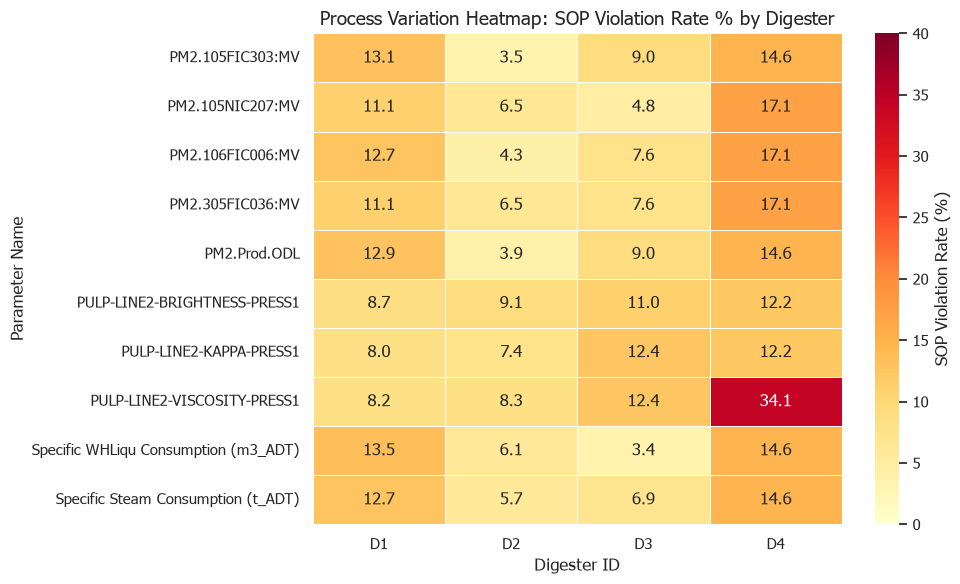

In [23]:
# 2. Plot Process Variation Heatmap: SOP Violation Rate % by Digester
import os

if 'Digester_ID' in df_wide.columns:
    numeric_df = df_wide.select_dtypes(include=[np.number]).copy()
    numeric_df['Digester_ID'] = df_wide['Digester_ID']
    
    # Exclude status, std, and non-process metadata columns
    exclude_keywords = ['STATUS', 'CLUSTER', 'BLOCK_ID', 'ROW_COUNT', 'DURATION_MIN', '_STD']
    clean_params = [c for c in numeric_df.columns if c != 'Digester_ID' and not any(kw in c.upper() for kw in exclude_keywords)]
    
    # Load or calculate SOP limits
    sop_limits_file = 'sop_limits_reference.xlsx'
    limits_lookup = {}
    
    if os.path.exists(sop_limits_file):
        df_limits = pd.read_excel(sop_limits_file)
        for _, row in df_limits.iterrows():
            param_base = row['Parameter']
            limits_lookup[param_base] = (row['SOP_Lower_Limit (5th%)'], row['SOP_Upper_Limit (95th%)'])
            limits_lookup[f"{param_base}_mean"] = (row['SOP_Lower_Limit (5th%)'], row['SOP_Upper_Limit (95th%)'])
            
    # Calculate SOP Violation Rate (%) per parameter and Digester
    violation_rates = {}
    clean_labels = {}
    for param in clean_params:
        if param in limits_lookup:
            low, high = limits_lookup[param]
        else:
            # Fallback to 5th and 95th percentiles of current dataset
            valid_vals = numeric_df[param].dropna()
            low = valid_vals.quantile(0.05) if len(valid_vals) > 0 else 0
            high = valid_vals.quantile(0.95) if len(valid_vals) > 0 else 100
            
        param_rates = {}
        for dig in ['D1', 'D2', 'D3', 'D4']:
            dig_vals = numeric_df[numeric_df['Digester_ID'] == dig][param].dropna()
            if len(dig_vals) > 0:
                violations = ((dig_vals < low) | (dig_vals > high)).sum()
                rate = (violations / len(dig_vals)) * 100
                param_rates[dig] = rate
            else:
                param_rates[dig] = np.nan
                
        # Clean label (strip _mean suffix if present)
        display_label = param[:-5] if param.endswith('_mean') else param
        violation_rates[display_label] = param_rates
        
    heatmap_data = pd.DataFrame(violation_rates).T
    col_order = [d for d in ['D1', 'D2', 'D3', 'D4'] if d in heatmap_data.columns]
    heatmap_data = heatmap_data[col_order]
    
    if not heatmap_data.empty:
        plt.figure(figsize=(10, max(6, len(heatmap_data) * 0.45)))
        sns.heatmap(
            heatmap_data,
            annot=True,
            fmt=".1f",
            cmap="YlOrRd",
            vmin=0,
            vmax=40,
            linewidths=0.5,
            cbar_kws={'label': 'SOP Violation Rate (%)'}
        )
        plt.title('Process Variation Heatmap: SOP Violation Rate % by Digester', fontsize=14, fontweight='normal')
        plt.xlabel('Digester ID', fontsize=12, fontweight='normal')
        plt.ylabel('Parameter Name', fontsize=12, fontweight='normal')
        plt.tight_layout()
        plt.show()
    else:
        print("⚠️ No valid process parameters found for SOP violation heatmap plotting.")
else:
    print("⚠️ Digester_ID column unavailable for heatmap plotting.")

### 8. Process & Quality Correlation Matrix Analysis

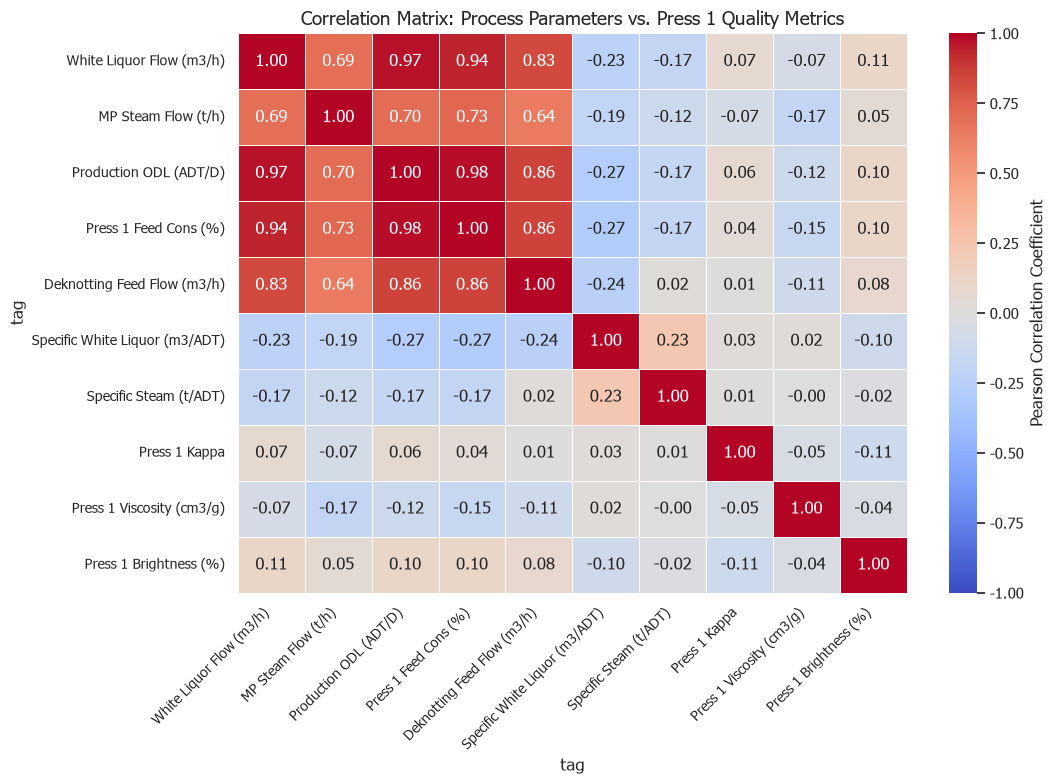

In [26]:
# Friendly Name Mapping for PI Tags & Process Parameters
TAG_LABELS = {
    "PM2.105FIC303:MV": "White Liquor Flow (m3/h)",
    "PM2.305FIC036:MV": "MP Steam Flow (t/h)",
    "PM2.Prod.ODL": "Production ODL (ADT/D)",
    "PM2.105NIC207:MV": "Press 1 Feed Cons (%)",
    "PM2.106FIC006:MV": "Deknotting Feed Flow (m3/h)",
    "Specific WHLiqu Consumption (m3_ADT)": "Specific White Liquor (m3/ADT)",
    "Specific Steam Consumption (t_ADT)": "Specific Steam (t/ADT)",
    "PULP-LINE2-KAPPA-PRESS1": "Press 1 Kappa",
    "PULP-LINE2-VISCOSITY-PRESS1": "Press 1 Viscosity (cm3/g)",
    "PULP-LINE2-BRIGHTNESS-PRESS1": "Press 1 Brightness (%)",
    # Mappings for local fallback dataset
    "WHLiqu to DilSrew_White liquor (m3/h)_mean": "White Liquor Flow (m3/h)",
    "MP Steam Pulp Heat_Feed before Reactor 2 (t/h)_mean": "MP Steam Flow (t/h)",
    "Production ODL (ADT/D)_mean": "Production ODL (ADT/D)",
    "Press 1 Feed Cons (%)_mean": "Press 1 Feed Cons (%)",
    "Deknotting Feed Flow (m3/h)_mean": "Deknotting Feed Flow (m3/h)",
    "Specific WHLiqu Consumption (m3_ADT)_mean": "Specific White Liquor (m3/ADT)",
    "Specific Steam Consumption (t_ADT)_mean": "Specific Steam (t/ADT)",
    "Pre O2 Kappa_Kappa online (%)_mean": "Pre O2 Kappa Online",
    "Post O2 Kappa_Kappa online (%)_mean": "Post O2 Kappa Online"
}

target_corr_tags = [
    # Process Inputs
    "PM2.105FIC303:MV",
    "PM2.305FIC036:MV",
    "PM2.Prod.ODL",
    "PM2.105NIC207:MV",
    "PM2.106FIC006:MV",
    # Specific Consumptions
    "Specific WHLiqu Consumption (m3_ADT)",
    "Specific Steam Consumption (t_ADT)",
    # Quality Outputs
    "PULP-LINE2-KAPPA-PRESS1",
    "PULP-LINE2-VISCOSITY-PRESS1",
    "PULP-LINE2-BRIGHTNESS-PRESS1"
]

# Check available columns in df_wide
avail_corr_cols = [c for c in target_corr_tags if c in df_wide.columns]

# Fallback check for local batch signatures if API tags not matched
if len(avail_corr_cols) < 3:
    avail_corr_cols = [c for c in df_wide.select_dtypes(include=[np.number]).columns 
                      if not any(kw in c.upper() for kw in ['STATUS', 'CLUSTER', 'BLOCK_ID', 'ROW_COUNT', 'DURATION_MIN', '_STD'])]

if len(avail_corr_cols) >= 2:
    # Compute Pearson Correlation Matrix
    corr_matrix = df_wide[avail_corr_cols].corr()
    
    # Rename index and columns to friendly names
    corr_matrix_renamed = corr_matrix.rename(index=TAG_LABELS, columns=TAG_LABELS)
    
    plt.figure(figsize=(11, 8))
    sns.heatmap(
        corr_matrix_renamed,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1.0,
        vmax=1.0,
        linewidths=0.5,
        cbar_kws={'label': 'Pearson Correlation Coefficient'}
    )
    plt.title('Correlation Matrix: Process Parameters vs. Press 1 Quality Metrics', fontsize=14, fontweight='normal')
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()
else:
    print(" Not enough numeric parameters available to compute Correlation Matrix.")

### 9. Digester-Specific Correlation Breakdown (D1, D2, D3, D4)

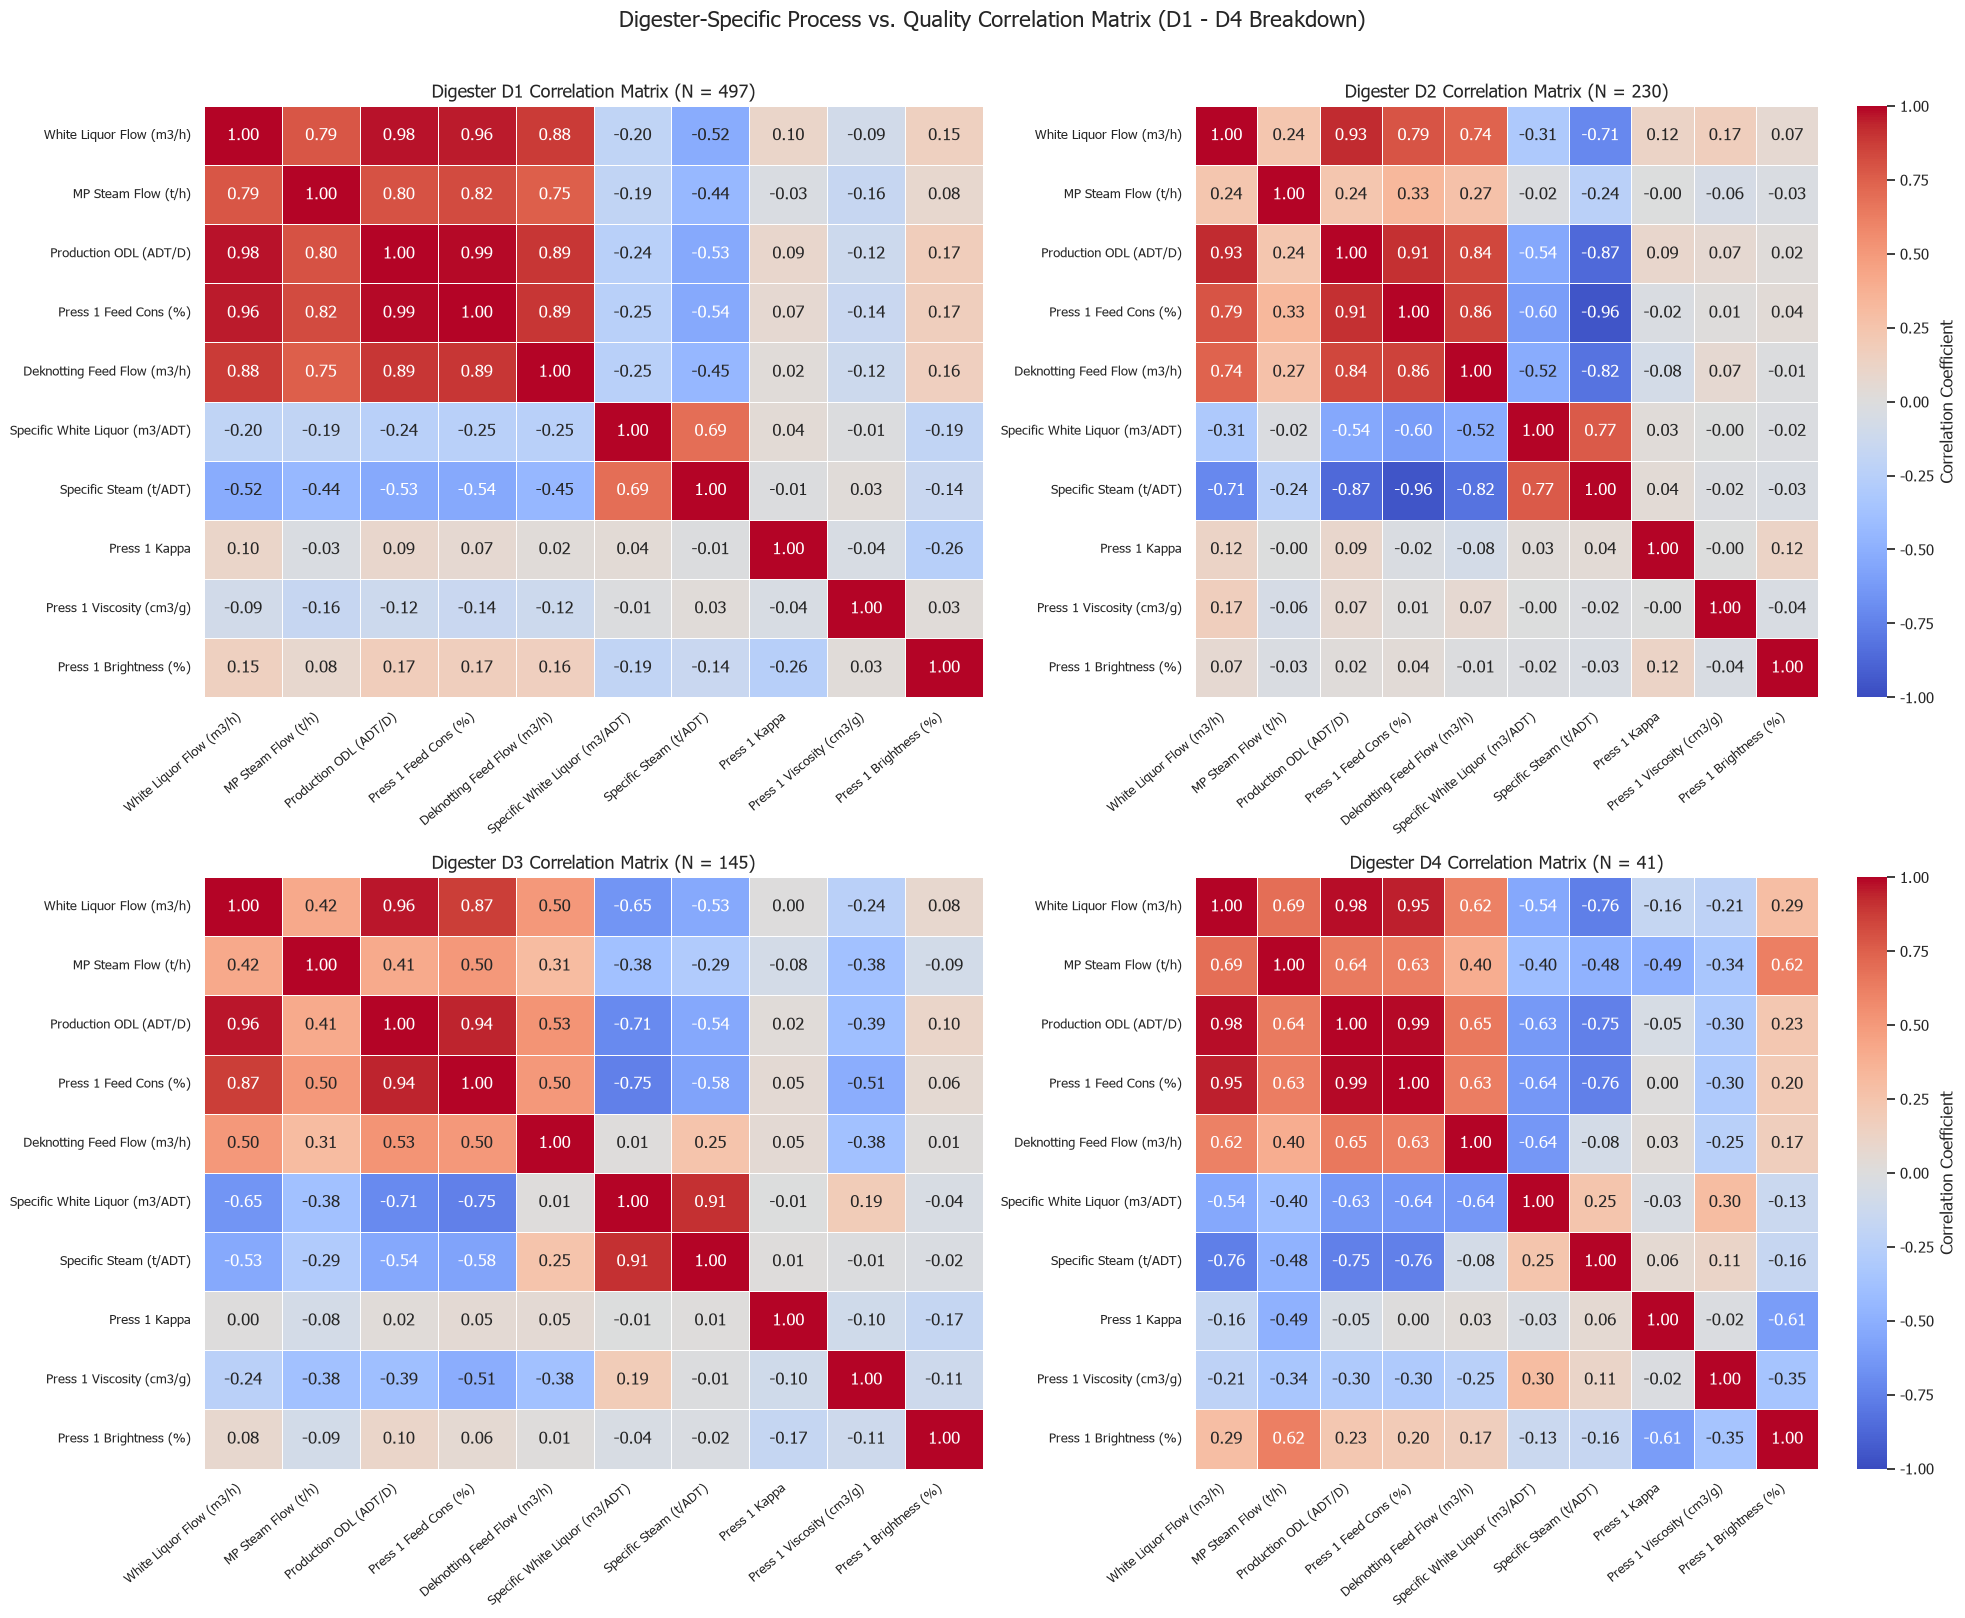

In [27]:
# Plot Digester-Specific Correlation Matrices (2x2 Grid for D1, D2, D3, D4)
if 'Digester_ID' in df_wide.columns and len(avail_corr_cols) >= 2:
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))
    axes = axes.flatten()
    digester_list = ['D1', 'D2', 'D3', 'D4']
    
    for idx, dig in enumerate(digester_list):
        ax = axes[idx]
        df_sub = df_wide[df_wide['Digester_ID'] == dig][avail_corr_cols].dropna(how='all')
        
        if len(df_sub) > 5:
            # Compute correlation for this specific digester
            corr_sub = df_sub.corr()
            corr_sub_renamed = corr_sub.rename(index=TAG_LABELS, columns=TAG_LABELS)
            
            sns.heatmap(
                corr_sub_renamed,
                annot=True,
                fmt=".2f",
                cmap="coolwarm",
                vmin=-1.0,
                vmax=1.0,
                linewidths=0.5,
                cbar=(idx == 1 or idx == 3),
                cbar_kws={'label': 'Correlation Coefficient'} if (idx == 1 or idx == 3) else None,
                ax=ax
            )
            ax.set_title(f'Digester {dig} Correlation Matrix (N = {len(df_sub)})', fontsize=13, fontweight='normal')
            ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right', fontsize=9)
            ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
            ax.set_xlabel('')
            ax.set_ylabel('')
        else:
            ax.text(0.5, 0.5, f'Insufficient Data for {dig}\n(N = {len(df_sub)})', 
                    ha='center', va='center', fontsize=12, color='gray')
            ax.set_title(f'Digester {dig} (No Data)', fontsize=13)
            ax.axis('off')
            
    plt.suptitle('Digester-Specific Process vs. Quality Correlation Matrix (D1 - D4 Breakdown)', fontsize=16, y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Digester_ID or valid numeric columns unavailable for digester-specific correlation.")

### 10. D4 Verification: Steam-Production Mismatch vs. Low Kappa Analysis

In [ ]:
# Verification Plots for Digester 4: Steam & Production Mismatch vs. Press 1 Quality
df_d4 = df_wide[df_wide['Digester_ID'] == 'D4'].copy()

steam_tag_name = "PM2.305FIC036:MV" if "PM2.305FIC036:MV" in df_d4.columns else [c for c in df_d4.columns if 'STEAM' in c.upper()][0]
prod_tag_name = "PM2.Prod.ODL" if "PM2.Prod.ODL" in df_d4.columns else [c for c in df_d4.columns if 'PROD' in c.upper()][0]
spec_steam_name = "Specific Steam Consumption (t_ADT)" if "Specific Steam Consumption (t_ADT)" in df_d4.columns else [c for c in df_d4.columns if 'Specific Steam' in c][0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# 1. Plot Dual-Axis Time Series Trend for D4
ax1_twin = ax1.twinx()
valid_d4 = df_d4.dropna(subset=[prod_tag_name, steam_tag_name, kappa_col]) if kappa_col in df_d4.columns else df_d4

time_axis = valid_d4['timestamp'] if 'timestamp' in valid_d4.columns else valid_d4.index

line1 = ax1.plot(time_axis, valid_d4[prod_tag_name], color='tab:orange', label='Production Rate (ADT/D)', linewidth=1.5)
line2 = ax1.plot(time_axis, valid_d4[steam_tag_name] * 200, color='tab:blue', linestyle='--', label='Steam Flow (x200 scaled t/h)', linewidth=1.5)

if kappa_col and kappa_col in valid_d4.columns:
    line3 = ax1_twin.plot(time_axis, valid_d4[kappa_col], color='tab:red', label='Press 1 Kappa', linewidth=2.0)
    ax1_twin.axhline(10.0, color='gray', linestyle=':', label='Target Kappa = 10.0')
    ax1_twin.set_ylabel('Press 1 Kappa', color='tab:red', fontsize=11)
    ax1_twin.grid(False)

ax1.set_title('Digester 4 Timeline: Production Drop vs. Steam Hold vs. Kappa Response', fontsize=13, fontweight='normal')
ax1.set_xlabel('Timestamp / Time Order', fontsize=11)
ax1.set_ylabel('Production (ADT/D) & Scaled Steam', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

lines = line1 + line2 + (line3 if kappa_col and kappa_col in valid_d4.columns else [])
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

# 2. Scatter Plot: Specific Steam vs. Press 1 Kappa (Colored by Production Rate)
if kappa_col and kappa_col in df_d4.columns and spec_steam_name in df_d4.columns:
    scatter = ax2.scatter(
        df_d4[spec_steam_name],
        df_d4[kappa_col],
        c=df_d4[prod_tag_name],
        cmap='viridis_r',
        s=80,
        alpha=0.8,
        edgecolor='black',
        linewidth=0.5
    )
    cbar = plt.colorbar(scatter, ax=ax2)
    cbar.set_label('Production Rate (ADT/D)', fontsize=10)
    
    ax2.axhline(10.0, color='red', linestyle='--', label='Target Kappa = 10.0')
    ax2.set_title('Digester 4: Specific Steam vs. Kappa (Color = Production Rate)', fontsize=13, fontweight='normal')
    ax2.set_xlabel('Specific Steam Consumption (t/ADT)', fontsize=11)
    ax2.set_ylabel('Press 1 Kappa', fontsize=11)
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()